In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

In [2]:
TICKERS = ["SPY", "TLT", "GLD", "BTC-USD"]

START_DATE = "2015-01-01"
END_DATE = "2026-10-01"


In [3]:
DATA_FILE = "data/raw/prices.csv"

if os.path.exists(DATA_FILE):

    print("Using saved market data:")
    print(DATA_FILE)

    prices_common = pd.read_csv(
        DATA_FILE,
        index_col=0,
        parse_dates=True
    )

else:

    print("Saved data not found.")
    print("Downloading from Yahoo Finance...")

    price_series = []

    for ticker in TICKERS:

        print(f"Downloading {ticker}...")

        df = yf.download(
            ticker,
            start=START_DATE,
            end=END_DATE,
            auto_adjust=True,
            progress=False,
            threads=False
        )

        if df.empty:
            raise ValueError(
                f"No data downloaded for {ticker}"
            )

        if isinstance(
            df.columns,
            pd.MultiIndex
        ):
            close = df["Close"].iloc[:, 0]
        else:
            close = df["Close"]

        close = close.rename(ticker)

        price_series.append(close)

    prices_common = pd.concat(
        price_series,
        axis=1,
        join="inner"
    )

    prices_common = prices_common.dropna()

    prices_common.to_csv(
        DATA_FILE
    )

    print("Downloaded and saved successfully.")

Saved data not found.


Downloaded and saved successfully.


In [4]:
prices_common = prices_common[
    [
        "SPY",
        "TLT",
        "GLD",
        "BTC-USD"
    ]
]

prices_common = prices_common.dropna()

print("\nFinal shape:")
print(prices_common.shape)

print("\nMissing values:")
print(prices_common.isna().sum())

print("\nFirst rows:")
print(prices_common.head())


Final shape:
(2953, 4)

Missing values:
SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64

First rows:
                   SPY        TLT         GLD     BTC-USD
2015-01-02  169.267563  91.566437  114.080002  315.032013
2015-01-05  166.210556  93.004784  115.800003  274.473999
2015-01-06  164.645096  94.680511  117.120003  286.188995
2015-01-07  166.696732  94.493500  116.430000  294.337006
2015-01-08  169.654816  93.242180  115.940002  283.348999


In [5]:
prices_common.isna().sum()

SPY        0
TLT        0
GLD        0
BTC-USD    0
dtype: int64

In [6]:
print("Start date:", prices_common.index.min())
print("End date:", prices_common.index.max())
print("Number of observations:", len(prices_common))

Start date: 2015-01-02 00:00:00
End date: 2026-09-30 00:00:00
Number of observations: 2953


In [7]:
prices_common.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2953 entries, 2015-01-02 to 2026-09-30
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPY      2953 non-null   float64
 1   TLT      2953 non-null   float64
 2   GLD      2953 non-null   float64
 3   BTC-USD  2953 non-null   float64
dtypes: float64(4)
memory usage: 115.4 KB


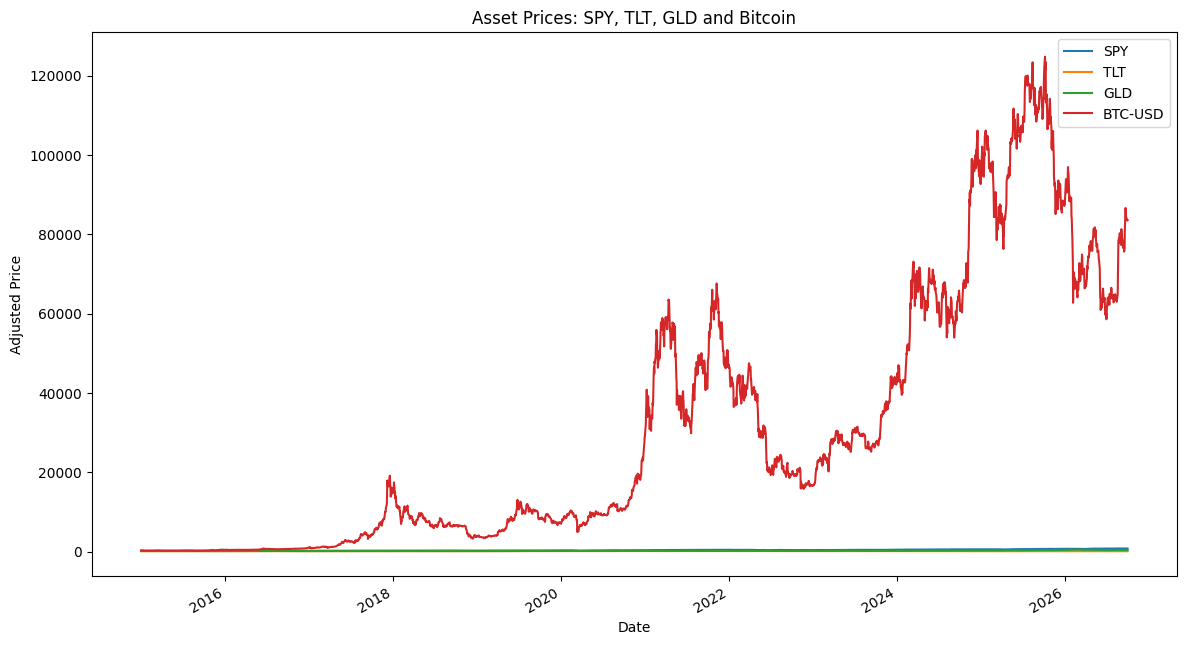

In [8]:
prices_common.plot(
    figsize=(14, 8),
    title="Asset Prices: SPY, TLT, GLD and Bitcoin"
)

plt.xlabel("Date")
plt.ylabel("Adjusted Price")
plt.show()

In [9]:
if prices_common.empty:
    raise ValueError(
        "prices_common is empty. Check the ticker downloads above."
    )

In [10]:
normalized_prices = (
    prices_common
    / prices_common.iloc[0]
) * 100

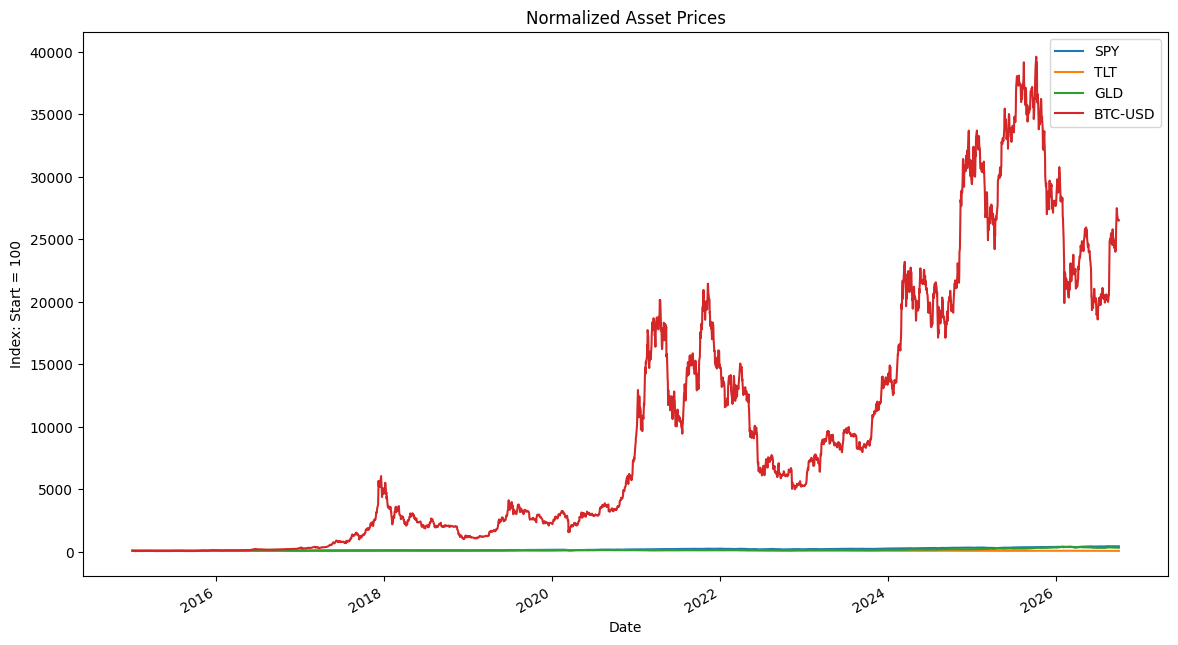

In [11]:
normalized_prices.plot(
    figsize=(14, 8),
    title="Normalized Asset Prices"
)

plt.xlabel("Date")
plt.ylabel("Index: Start = 100")
plt.show()

In [12]:
prices_common.to_csv("data/raw/prices.csv")

In [13]:
check = pd.read_csv(
    "data/raw/prices.csv",
    index_col=0,
    parse_dates=True
)

check.head()

,SPY,TLT,GLD,BTC-USD
2015-01-02,169.267563,91.566437,114.080002,315.032013
2015-01-05,166.210556,93.004784,115.800003,274.473999
2015-01-06,164.645096,94.680511,117.120003,286.188995
2015-01-07,166.696732,94.493500,116.430000,294.337006
2015-01-08,169.654816,93.242180,115.940002,283.348999


In [14]:
prices_common.to_csv("data/raw/prices.csv")